# Task 2 — Proposed attention model (CBAM-ResNet50) on BUSI-WHU
**Group08** | Dataset: BUSI-WHU breast ultrasound (benign vs malignant) | Same patient-wise split and training settings as the baseline notebook.

## 0. Setup

In [4]:
# ---- 0. SETUP -------------------------------------------------------------
import os, re, time, copy, random, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision, torchvision.transforms.functional as TF
from torchvision import models
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score, average_precision_score,
                             f1_score, accuracy_score, roc_curve, precision_recall_curve)
warnings.filterwarnings('ignore'); sns.set_theme(style='whitegrid')

os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'
SEED = 42
def seed_everything(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_everything()
torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True, warn_only=True)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
USE_AMP = DEVICE == 'cuda'

# ---- ACTUAL KAGGLE DATASET PATH ------------------------------------------
DATA_DIR = ("/kaggle/input/datasets/maharuntanni/"
            "busi-whu-breast-cancer-ultrasound-image-dataset/"
            "BUSI_WHU Breast Cancer Ultrasound Image  Dataset")
XLSX_PATH = f"{DATA_DIR}/Patient_infos_BUSI-WHU.xlsx"
OUT_DIR = Path('/kaggle/working/task2_outputs') if os.path.isdir('/kaggle') else Path('task2_outputs')
OUT_DIR.mkdir(parents=True, exist_ok=True)
CLASSES = ['benign', 'malignant']
print('Device:', DEVICE, '| torch', torch.__version__, '| output dir:', OUT_DIR)
print('Dataset folder exists:', os.path.isdir(DATA_DIR), '| Excel exists:', os.path.isfile(XLSX_PATH))

Device: cuda | torch 2.11.0+cu130 | output dir: /kaggle/working/task2_outputs
Dataset folder exists: True | Excel exists: True


## 1. Data

In [9]:
# ---- 1. LOAD IMAGES + LABELS + PATIENT IDS -------------------------------
img_files = sorted(Path(DATA_DIR).rglob('img/*.bmp'))
meta = pd.read_excel(XLSX_PATH)
meta.columns = [str(c).replace('\n', ' ').strip() for c in meta.columns]
LAB_COL = next(c for c in meta.columns if 'malignant' in c.lower())
meta['stem'] = meta['img_names'].astype(str).str.strip().str.replace(r'\.[A-Za-z0-9]+$', '', regex=True)
assert meta.stem.is_unique, 'image names in the Excel file are not unique'
df = pd.DataFrame({'path': [str(p) for p in img_files], 'stem': [p.stem for p in img_files]})
df = df.merge(meta[['stem', 'patient_index', LAB_COL]], on='stem', how='left')
assert len(df) == len(img_files), 'merge changed the number of images'
assert df[LAB_COL].notna().all(), 'some images have no label in the Excel file'
df['y'] = df[LAB_COL].astype(int)
y_all = df.y.values
print('Images:', len(df), '| patients:', df.patient_index.nunique())
print(df.y.map({0: 'benign', 1: 'malignant'}).value_counts().to_string())

Images: 927 | patients: 816
y
benign       560
malignant    367


## 2. Preprocessing

In [11]:
# ---- 2. PREPROCESSING: grayscale -> square letterbox (keeps tumour shape) -> 224x224 ----
IMG = 224
def load_letterbox(p):
    im = Image.open(p).convert('L'); w, h = im.size; s = IMG / max(w, h)
    im = im.resize((max(1, round(w * s)), max(1, round(h * s))), Image.BILINEAR)
    canvas = Image.new('L', (IMG, IMG), 0)
    canvas.paste(im, ((IMG - im.size[0]) // 2, (IMG - im.size[1]) // 2))
    return np.array(canvas)
X_all = np.stack([load_letterbox(p) for p in df.path])           # N x 224 x 224, uint8
print('Cached array:', X_all.shape, X_all.dtype)
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1); STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

Cached array: (927, 224, 224) uint8


## 3. Patient-wise split (identical to the baseline notebook), augmentation, class weights

In [15]:
# ---- 3. SPLIT BY PATIENT (no patient appears in two sets), stratified by class ----
sgkf = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=SEED)
folds = [te for _, te in sgkf.split(df, y_all, groups=df.patient_index)]
test_idx, val_idx = folds[0], folds[1]
train_idx = np.concatenate(folds[2:])
df['split'] = 'train'; df.loc[val_idx, 'split'] = 'val'; df.loc[test_idx, 'split'] = 'test'
pat = {s: set(df[df.split == s].patient_index) for s in ['train', 'val', 'test']}
assert not (pat['train'] & pat['val']) and not (pat['train'] & pat['test']) and not (pat['val'] & pat['test'])
print('Patient overlap between sets: 0  (checked)')
print(pd.crosstab(df.split, df.y.map({0: 'benign', 1: 'malignant'}), margins=True))
df[['stem', 'patient_index', 'y', 'split']].to_csv(OUT_DIR / 'splits.csv', index=False)

class BUSIData(Dataset):
    def __init__(self, idx, train=False):
        self.X, self.y, self.train = X_all[idx], y_all[idx], train
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        x = torch.from_numpy(self.X[i]).float().div(255).unsqueeze(0)       # 1 x H x W
        if self.train:                                                       # light augmentation (no strong crops)
            if random.random() < 0.5: x = torch.flip(x, [2])
            x = TF.affine(x, angle=random.uniform(-10, 10),
                          translate=[int(random.uniform(-.05, .05) * IMG), int(random.uniform(-.05, .05) * IMG)],
                          scale=random.uniform(0.9, 1.1), shear=[0.0, 0.0],
                          interpolation=TF.InterpolationMode.BILINEAR)
            x = ((x - 0.5) * random.uniform(0.85, 1.15) + 0.5 + random.uniform(-0.08, 0.08)).clamp(0, 1)
        x = (x.repeat(3, 1, 1) - MEAN) / STD
        return x, int(self.y[i])

BS = 32
train_dl = DataLoader(BUSIData(train_idx, True), batch_size=BS, shuffle=True, num_workers=2, drop_last=True)
val_dl = DataLoader(BUSIData(val_idx), batch_size=64, num_workers=2)
test_dl = DataLoader(BUSIData(test_idx), batch_size=64, num_workers=2)
y_val, y_test = y_all[val_idx], y_all[test_idx]
cnt = np.bincount(y_all[train_idx]); CLASS_W = torch.tensor(cnt.sum() / (2 * cnt), dtype=torch.float32)
print('Class weights (benign, malignant):', CLASS_W.numpy().round(3))

Patient overlap between sets: 0  (checked)
y      benign  malignant  All
split                        
test      100         49  149
train     360        269  629
val       100         49  149
All       560        367  927
Class weights (benign, malignant): [0.874 1.169]


## 4. Training and evaluation helpers

In [22]:
# ---- 4. TRAINING / EVALUATION HELPERS -------------------------------------
@torch.no_grad()
def predict(model, dl):
    model.eval(); P, Y = [], []
    for xb, yb in dl:
        with torch.autocast(device_type=DEVICE, enabled=USE_AMP):
            out = model(xb.to(DEVICE, non_blocking=True))
        P.append(torch.softmax(out.float(), 1).cpu().numpy()); Y.append(yb.numpy())
    return np.concatenate(P), np.concatenate(Y)

def train_model(model, name, lr=1e-4, new_params=None, new_lr=None, epochs=25, patience=6, seed=SEED, verbose=True):
    seed_everything(seed)
    model.to(DEVICE)
    if new_params:
        ids = {id(p) for p in new_params}
        base = [p for p in model.parameters() if id(p) not in ids]
        groups = [{'params': base, 'lr': lr}, {'params': new_params, 'lr': new_lr or lr}]
    else:
        groups = [{'params': model.parameters(), 'lr': lr}]
    opt = torch.optim.AdamW(groups, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    crit = nn.CrossEntropyLoss(weight=CLASS_W.to(DEVICE))
    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
    best, best_state, bad, hist = -1, None, 0, []
    if DEVICE == 'cuda': torch.cuda.synchronize()
    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train(); tl = 0.0
        for xb, yb in train_dl:
            xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE, enabled=USE_AMP):
                loss = crit(model(xb), yb)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tl += loss.item() * len(yb)
        sched.step()
        vp, vy = predict(model, val_dl)
        vf1 = f1_score(vy, vp.argmax(1), average='macro')
        vloss = float(F.nll_loss(torch.log(torch.tensor(vp) + 1e-8), torch.tensor(vy), weight=CLASS_W))
        hist.append(dict(epoch=ep, train_loss=tl / (len(train_dl) * BS), val_loss=vloss, val_macro_f1=vf1))
        if vf1 > best: best, best_state, bad = vf1, copy.deepcopy(model.state_dict()), 0
        else: bad += 1
        if verbose: print(f'[{name}] epoch {ep:02d} | train loss {hist[-1]["train_loss"]:.4f} | val macro-F1 {vf1:.4f}' + ('  *' if bad == 0 else ''))
        if bad >= patience:
            if verbose: print(f'[{name}] early stop (best val macro-F1 {best:.4f})')
            break
    if DEVICE == 'cuda': torch.cuda.synchronize()
    train_time = time.time() - t0
    model.load_state_dict(best_state)
    return model, pd.DataFrame(hist), train_time

def evaluate(name, model, train_time, pretrained, verbose=True):
    t0 = time.time(); probs, y = predict(model, test_dl)
    if DEVICE == 'cuda': torch.cuda.synchronize()
    infer_ms = (time.time() - t0) / len(y) * 1000
    pred = probs.argmax(1)
    rep = classification_report(y, pred, target_names=CLASSES, output_dict=True)
    n_par = sum(p.numel() for p in model.parameters())
    row = dict(model=name, pretrained=pretrained, accuracy=accuracy_score(y, pred),
               precision_macro=rep['macro avg']['precision'], recall_macro=rep['macro avg']['recall'],
               f1_macro=rep['macro avg']['f1-score'], f1_weighted=rep['weighted avg']['f1-score'],
               recall_benign=rep['benign']['recall'], recall_malignant=rep['malignant']['recall'],
               roc_auc=roc_auc_score(y, probs[:, 1]), pr_auc=average_precision_score(y, probs[:, 1]),
               train_time_s=train_time, params_M=n_par / 1e6, size_MB=n_par * 4 / 1e6, infer_ms_per_img=infer_ms)
    if verbose:
        print(f'\n=== {name}: test set ===')
        print(classification_report(y, pred, target_names=CLASSES, digits=3))
    return row, probs

SEEDS = [42, 7, 2024]
SUM_COLS = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro', 'f1_weighted', 'recall_benign', 'recall_malignant', 'roc_auc', 'pr_auc', 'best_val_f1']

def summarize(runs):
    """mean +- std over seeds for every model"""
    rows = []
    for n, g in runs.groupby('model', sort=False):
        r = {'model': n, 'n_seeds': len(g)}
        for c in SUM_COLS: r[c] = f'{g[c].mean():.3f} +- {g[c].std():.3f}'
        for c in ['train_time_s', 'params_M', 'size_MB', 'infer_ms_per_img']: r[c] = round(g[c].mean(), 2)
        rows.append(r)
    return pd.DataFrame(rows).set_index('model')

def build_torchvision(ctor, weights_enum, head_fn):
    """Build a pretrained torchvision model; fall back to random init if weights cannot be downloaded."""
    try:
        m, pre = ctor(weights=weights_enum.DEFAULT), True
    except Exception as e:
        print('  (could not download pretrained weights -> random init):', str(e)[:80])
        m, pre = ctor(weights=None), False
    return head_fn(m), pre

def plot_curves(names, probs_dict, y, fname, title):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
    for n in names:
        fpr, tpr, _ = roc_curve(y, probs_dict[n][:, 1]); ax[0].plot(fpr, tpr, label=f'{n} (AUC {roc_auc_score(y, probs_dict[n][:, 1]):.3f})')
        pr, rc, _ = precision_recall_curve(y, probs_dict[n][:, 1]); ax[1].plot(rc, pr, label=f'{n} (AP {average_precision_score(y, probs_dict[n][:, 1]):.3f})')
    ax[0].plot([0, 1], [0, 1], 'k--', lw=.8); ax[0].set(xlabel='False positive rate', ylabel='True positive rate', title='ROC curves (malignant = positive)')
    ax[1].set(xlabel='Recall', ylabel='Precision', title='Precision-recall curves (malignant = positive)')
    ax[0].legend(fontsize=8); ax[1].legend(fontsize=8); plt.suptitle(title, y=1.02)
    plt.tight_layout(); plt.savefig(OUT_DIR / fname, dpi=150, bbox_inches='tight'); plt.show()

def plot_confusions(names, probs_dict, y, fname):
    fig, ax = plt.subplots(1, len(names), figsize=(3.6 * len(names), 3.6), squeeze=False)
    for a, n in zip(ax[0], names):
        cm = confusion_matrix(y, probs_dict[n].argmax(1))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, xticklabels=CLASSES, yticklabels=CLASSES, ax=a)
        a.set(title=n, xlabel='Predicted', ylabel='True')
    plt.tight_layout(); plt.savefig(OUT_DIR / fname, dpi=150); plt.show()

def plot_history(hists, fname):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for n, h in hists.items():
        ax[0].plot(h.epoch, h.train_loss, label=n); ax[1].plot(h.epoch, h.val_macro_f1, label=n)
    ax[0].set(xlabel='Epoch', ylabel='Training loss', title='Training loss'); ax[1].set(xlabel='Epoch', ylabel='Validation macro-F1', title='Validation macro-F1')
    ax[0].legend(fontsize=8); ax[1].legend(fontsize=8); plt.tight_layout(); plt.savefig(OUT_DIR / fname, dpi=150); plt.show()

## 5. Proposed model: CBAM-ResNet50

**What it is.** A ResNet50 feature extractor with a CBAM attention block (channel attention followed by spatial attention) placed after each of the four residual stages, followed by global average pooling, dropout and a 2-class linear layer. Two versions of the block are compared:
- **standard**: output = F x channel weights x spatial weights (the original CBAM form);
- **residual**: output = F + (F x channel weights x spatial weights), so the pretrained features always pass through and attention only adds a refinement. This matters because the attention weights start random while the ResNet50 weights are already trained; multiplying pretrained features by random gates can disturb them early in fine-tuning.

The variant with the higher mean validation macro-F1 over the seeds is used as the proposed model (the test set is not used to choose).

**Why this attention type (CBAM = channel + spatial, hybrid).**
- Ultrasound images contain strong speckle noise, shadowing and a lot of background. *Spatial attention* learns a map over the image that gives more weight to the lesion region and less to background tissue.
- *Channel attention* re-weights the feature maps, so texture and margin features that matter for benign vs malignant get more weight than noisy ones.
- It adds very few parameters (about 0.7 M on top of 23.5 M), so any change comes from where the network looks, not from a much larger model.
- Placement after each stage lets early stages refine low-level texture and late stages refine lesion-level shape.

**How it works step by step.**
1. The image is resized and normalised and passed through the ResNet50 stem and stage 1.
2. CBAM block, channel attention: average-pool and max-pool each feature map over space, pass both through a shared small MLP, add them and apply a sigmoid. This gives one weight per channel that multiplies the features.
3. CBAM block, spatial attention: average and max over channels, stack the two maps, apply a 7x7 convolution and a sigmoid. This gives one weight per pixel that multiplies the features again.
4. Steps 2-3 are repeated after stages 2, 3 and 4, and the final features are pooled and classified.

**Why it should do better than plain ResNet50.** It is the same backbone with the same training setup, plus attention that can suppress background and speckle. Whether it really does is tested with three random seeds, because a single run on a small test set can change by several points just from randomness.

In [25]:
class ChannelAttention(nn.Module):
    def __init__(self, c, r=16):
        super().__init__()
        self.mlp = nn.Sequential(nn.Conv2d(c, c // r, 1, bias=False), nn.ReLU(inplace=True), nn.Conv2d(c // r, c, 1, bias=False))
    def forward(self, x):
        a = self.mlp(F.adaptive_avg_pool2d(x, 1)) + self.mlp(F.adaptive_max_pool2d(x, 1))
        return torch.sigmoid(a)

class SpatialAttention(nn.Module):
    def __init__(self, k=7):
        super().__init__(); self.conv = nn.Conv2d(2, 1, k, padding=k // 2, bias=False)
    def forward(self, x):
        return torch.sigmoid(self.conv(torch.cat([x.mean(1, keepdim=True), x.amax(1, keepdim=True)], 1)))

class CBAM(nn.Module):
    def __init__(self, c, r=16, residual=False):
        super().__init__()
        self.ca, self.sa, self.residual, self.last_sa = ChannelAttention(c, r), SpatialAttention(), residual, None
    def forward(self, x):
        out = x * self.ca(x)
        m = self.sa(out); self.last_sa = m.detach()
        out = out * m
        return x + out if self.residual else out

def build_cbam_resnet50(residual=False, drop=0.3):
    m, pre = build_torchvision(models.resnet50, models.ResNet50_Weights, lambda m: m)
    for name, c in [('layer1', 256), ('layer2', 512), ('layer3', 1024), ('layer4', 2048)]:
        setattr(m, name, nn.Sequential(getattr(m, name), CBAM(c, residual=residual)))
    m.fc = nn.Sequential(nn.Dropout(drop), nn.Linear(2048, 2))
    return m, pre

def build_plain_resnet50(drop=0.3):
    return build_torchvision(models.resnet50, models.ResNet50_Weights, lambda m: (setattr(m, 'fc', nn.Sequential(nn.Dropout(drop), nn.Linear(2048, 2))), m)[1])

PLAIN = 'ResNet50 (no attention)'
VARIANTS = {PLAIN: build_plain_resnet50,
            'CBAM-ResNet50 (standard)': lambda: build_cbam_resnet50(False),
            'CBAM-ResNet50 (residual)': lambda: build_cbam_resnet50(True)}
m_tmp, _ = build_cbam_resnet50()
n_att = sum(p.numel() for mod in m_tmp.modules() if isinstance(mod, CBAM) for p in mod.parameters())
print(f'CBAM-ResNet50 parameters: {sum(p.numel() for p in m_tmp.parameters())/1e6:.2f} M (attention adds {n_att/1e6:.2f} M)')
del m_tmp

CBAM-ResNet50 parameters: 24.21 M (attention adds 0.70 M)


### Architecture diagram

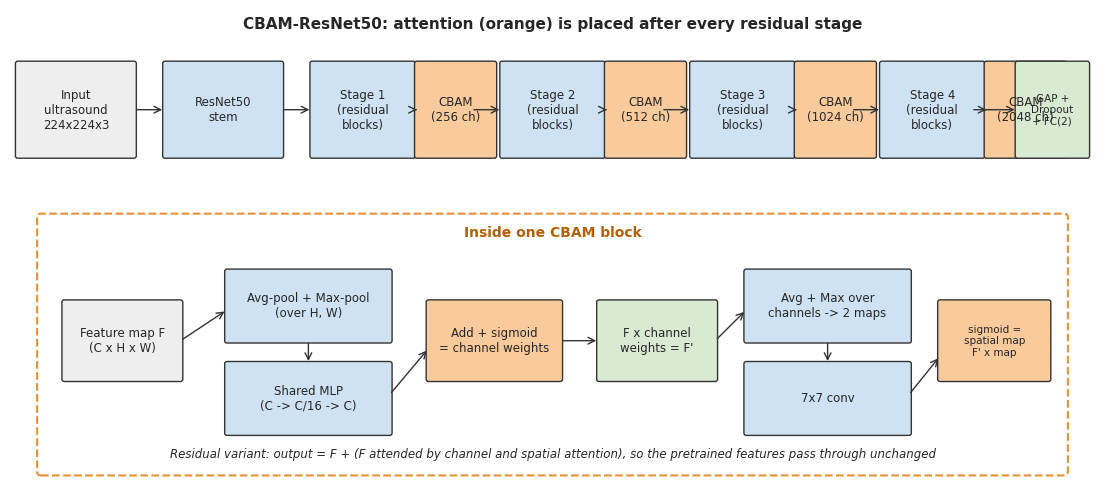

In [29]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
fig, ax = plt.subplots(figsize=(14, 6.2)); ax.set_xlim(0, 14); ax.set_ylim(0, 6.2); ax.axis('off')
def box(x, y, w, h, txt, fc, fs=8.5):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.03', fc=fc, ec='#333', lw=1))
    ax.text(x + w / 2, y + h / 2, txt, ha='center', va='center', fontsize=fs)
def arrow(x1, y1, x2, y2): ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle='->', mutation_scale=12, color='#333'))
blue, orange, green, grey = '#cfe2f3', '#f9cb9c', '#d9ead3', '#eeeeee'
box(0.1, 4.3, 1.5, 1.2, 'Input\nultrasound\n224x224x3', grey)
box(2.0, 4.3, 1.5, 1.2, 'ResNet50\nstem', blue); arrow(1.6, 4.9, 2.0, 4.9)
xs = 3.9
for i, c in enumerate([256, 512, 1024, 2048], 1):
    box(xs, 4.3, 1.3, 1.2, f'Stage {i}\n(residual\nblocks)', blue); arrow(xs - 0.4, 4.9, xs, 4.9)
    box(xs + 1.35, 4.3, 1.0, 1.2, f'CBAM\n({c} ch)', orange); arrow(xs + 1.3, 4.9, xs + 1.35, 4.9)
    xs += 2.45
box(13.0, 4.3, 0.9, 1.2, 'GAP +\nDropout\n+ FC(2)', green, 7.5); arrow(12.4, 4.9, 13.0, 4.9)
ax.text(7, 5.95, 'CBAM-ResNet50: attention (orange) is placed after every residual stage', ha='center', fontsize=11, weight='bold')
ax.add_patch(FancyBboxPatch((0.4, 0.2), 13.2, 3.3, boxstyle='round,pad=0.05', fc='none', ec='#e69138', lw=1.5, ls='--'))
ax.text(7, 3.25, 'Inside one CBAM block', ha='center', fontsize=10, weight='bold', color='#b45f06')
box(0.7, 1.4, 1.5, 1.0, 'Feature map F\n(C x H x W)', grey)
box(2.8, 1.9, 2.1, 0.9, 'Avg-pool + Max-pool\n(over H, W)', blue); box(2.8, 0.7, 2.1, 0.9, 'Shared MLP\n(C -> C/16 -> C)', blue)
box(5.4, 1.4, 1.7, 1.0, 'Add + sigmoid\n= channel weights', orange)
box(7.6, 1.4, 1.5, 1.0, 'F x channel\nweights = F\'', green)
box(9.5, 1.9, 2.1, 0.9, 'Avg + Max over\nchannels -> 2 maps', blue); box(9.5, 0.7, 2.1, 0.9, '7x7 conv', blue)
box(12.0, 1.4, 1.4, 1.0, 'sigmoid =\nspatial map\nF\' x map', orange, 7.5)
arrow(2.2, 1.9, 2.8, 2.3); arrow(3.85, 1.9, 3.85, 1.6); arrow(4.9, 1.2, 5.4, 1.8); arrow(7.1, 1.9, 7.6, 1.9); arrow(9.1, 1.9, 9.5, 2.3); arrow(10.55, 1.9, 10.55, 1.6); arrow(11.6, 1.2, 12.0, 1.7)
ax.text(7, 0.38, 'Residual variant: output = F + (F attended by channel and spatial attention), so the pretrained features pass through unchanged', ha='center', fontsize=8.5, style='italic')
plt.savefig(OUT_DIR / 'T2_proposed_architecture.png', dpi=160, bbox_inches='tight'); plt.show()

## 6. Train the plain ResNet50 and both attention variants (3 seeds each)
All three use the same split, settings and seeds, so the only difference is the attention block.

In [30]:
runs, probs, hists, kept = [], {}, {}, {}
for name, fn in VARIANTS.items():
    for sd in SEEDS:
        model, pre = fn()
        att = [p for mod in model.modules() if isinstance(mod, CBAM) for p in mod.parameters()]
        model, hist, tt = train_model(model, name, lr=1e-4, new_params=(att + list(model.fc.parameters())) if att else None,
                                      new_lr=5e-4 if att else None, seed=sd, verbose=False)
        row, p = evaluate(name, model, tt, pre, verbose=False)
        row.update(seed=sd, best_val_f1=hist.val_macro_f1.max(), epochs_run=len(hist)); runs.append(row)
        print(f'[{name}] seed {sd}: best val macro-F1 {row["best_val_f1"]:.3f} | test macro-F1 {row["f1_macro"]:.3f} | test ROC-AUC {row["roc_auc"]:.3f} | {len(hist)} epochs')
        if sd == SEEDS[0]: probs[name], hists[name], kept[name] = p, hist, model
        else: del model
        torch.cuda.empty_cache()
runs = pd.DataFrame(runs); runs.to_csv(OUT_DIR / 'proposed_runs.csv', index=False)
for n, h in hists.items(): h.to_csv(OUT_DIR / ('history_' + n.replace(' ', '_') + '.csv'), index=False)

[ResNet50 (no attention)] seed 42: best val macro-F1 0.797 | test macro-F1 0.720 | test ROC-AUC 0.739 | 15 epochs
[ResNet50 (no attention)] seed 7: best val macro-F1 0.860 | test macro-F1 0.734 | test ROC-AUC 0.814 | 14 epochs
[ResNet50 (no attention)] seed 2024: best val macro-F1 0.801 | test macro-F1 0.718 | test ROC-AUC 0.812 | 10 epochs
[CBAM-ResNet50 (standard)] seed 42: best val macro-F1 0.805 | test macro-F1 0.602 | test ROC-AUC 0.675 | 16 epochs
[CBAM-ResNet50 (standard)] seed 7: best val macro-F1 0.871 | test macro-F1 0.781 | test ROC-AUC 0.875 | 25 epochs
[CBAM-ResNet50 (standard)] seed 2024: best val macro-F1 0.788 | test macro-F1 0.683 | test ROC-AUC 0.757 | 11 epochs
[CBAM-ResNet50 (residual)] seed 42: best val macro-F1 0.813 | test macro-F1 0.706 | test ROC-AUC 0.805 | 10 epochs
[CBAM-ResNet50 (residual)] seed 7: best val macro-F1 0.851 | test macro-F1 0.753 | test ROC-AUC 0.841 | 25 epochs
[CBAM-ResNet50 (residual)] seed 2024: best val macro-F1 0.825 | test macro-F1 0.72

## 7. Does attention help? Proposed model vs plain ResNet50 and the baselines

In [35]:
cbam_names = [n for n in VARIANTS if n != PLAIN]
PROPOSED = runs[runs.model.isin(cbam_names)].groupby('model').best_val_f1.mean().idxmax()
print('Proposed model (attention variant with the higher mean validation macro-F1):', PROPOSED)

# optional: load the baseline notebook results (same split) if they are available
found = [OUT_DIR / 'baseline_runs.csv'] + (list(Path('/kaggle/input').rglob('baseline_runs.csv')) if Path('/kaggle/input').exists() else [])
found = [f for f in found if f.exists()]; bruns, z = None, None
if found:
    bruns = pd.read_csv(found[0]); print('Loaded baseline results from', found[0])
    zp = found[0].with_name('baseline_test_probs.npz')
    if zp.exists():
        z = np.load(zp); assert (z['y'] == y_test).all(), 'baseline notebook used a different test split'
else:
    print('baseline_runs.csv not found -> add the baseline notebook output as an input (or copy the file into', OUT_DIR, ') to compare with all baselines.')
all_runs = pd.concat([bruns, runs], ignore_index=True) if bruns is not None else runs
summ = summarize(all_runs); summ.to_csv(OUT_DIR / 'comparison_all_models.csv'); display(summ)

# paired comparison with the plain ResNet50, seed by seed
mets = ['f1_macro', 'roc_auc', 'pr_auc', 'recall_malignant']
base = runs[runs.model == PLAIN].sort_values('seed')[mets].values
diff = []
for n in cbam_names:
    d = runs[runs.model == n].sort_values('seed')[mets].values - base
    diff.append(dict(variant=n, **{f'd_{m}': f'{d[:, i].mean():+.3f} (sd {d[:, i].std(ddof=1):.3f})' for i, m in enumerate(mets)}, seeds_better_f1=f'{(d[:, 0] > 0).sum()} of {len(d)}'))
diff = pd.DataFrame(diff).set_index('variant'); diff.to_csv(OUT_DIR / 'attention_vs_plain.csv'); display(diff)

Proposed model (attention variant with the higher mean validation macro-F1): CBAM-ResNet50 (residual)
baseline_runs.csv not found -> add the baseline notebook output as an input (or copy the file into /kaggle/working/task2_outputs ) to compare with all baselines.


,n_seeds,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,recall_benign,recall_malignant,roc_auc,pr_auc,best_val_f1,train_time_s,params_M,size_MB,infer_ms_per_img
model,,,,,,,,,,,,,,,
ResNet50 (no attention),3,0.754 +- 0.014,0.726 +- 0.012,0.728 +- 0.016,0.724 +- 0.009,0.755 +- 0.009,0.803 +- 0.061,0.653 +- 0.089,0.788 +- 0.042,0.646 +- 0.037,0.820 +- 0.035,45.16,23.51,94.05,2.87
CBAM-ResNet50 (standard),3,0.743 +- 0.061,0.704 +- 0.075,0.685 +- 0.092,0.689 +- 0.090,0.733 +- 0.071,0.853 +- 0.006,0.517 +- 0.185,0.769 +- 0.101,0.654 +- 0.115,0.821 +- 0.044,71.07,24.21,96.84,3.15
CBAM-ResNet50 (residual),3,0.763 +- 0.008,0.735 +- 0.011,0.730 +- 0.036,0.728 +- 0.024,0.761 +- 0.014,0.827 +- 0.050,0.633 +- 0.122,0.810 +- 0.029,0.703 +- 0.018,0.830 +- 0.019,74.73,24.21,96.84,3.25


,d_f1_macro,d_roc_auc,d_pr_auc,d_recall_malignant,seeds_better_f1
variant,,,,,
CBAM-ResNet50 (standard),-0.035 (sd 0.082),-0.019 (sd 0.070),+0.008 (sd 0.084),-0.136 (sd 0.136),1 of 3
CBAM-ResNet50 (residual),+0.005 (sd 0.017),+0.022 (sd 0.047),+0.057 (sd 0.038),-0.020 (sd 0.074),2 of 3


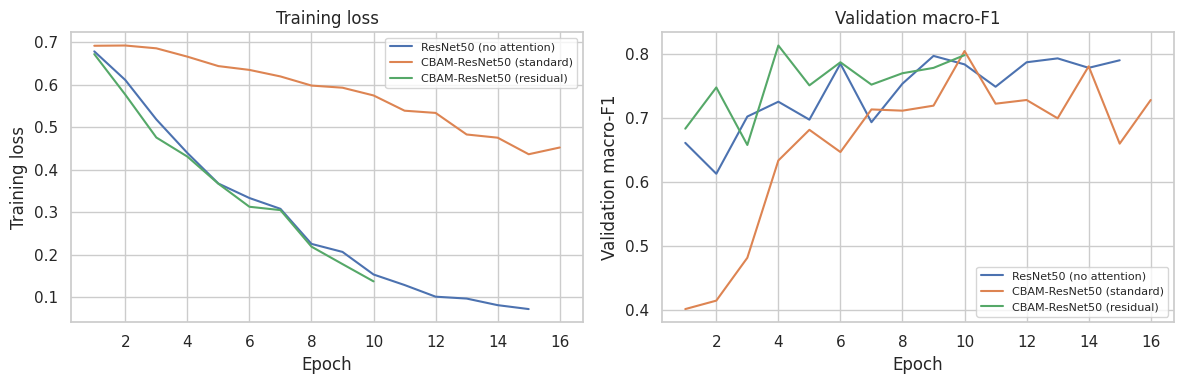

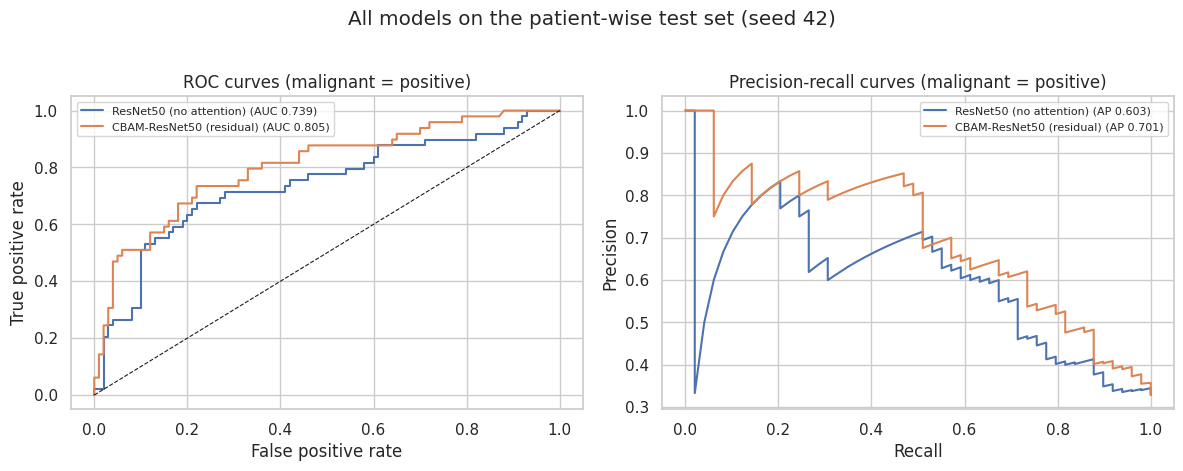

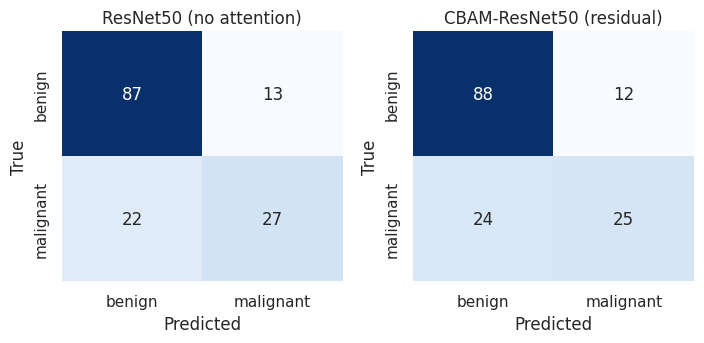

In [37]:
all_probs = {PLAIN: probs[PLAIN], PROPOSED: probs[PROPOSED]}
if z is not None:
    for n in bruns.model.unique(): all_probs[n] = z[n.replace('-', '_')]
plot_history(hists, 'T2_proposed_training_history.png')
plot_curves(list(all_probs), all_probs, y_test, 'T2_all_models_roc_pr.png', 'All models on the patient-wise test set (seed 42)')
plot_confusions([PLAIN, PROPOSED], all_probs, y_test, 'T2_proposed_confusion.png')

## 8. What does the attention look at?
Spatial-attention maps from stage 3 for some test images (red = high weight). This is a first look; the full explainability study (Grad-CAM, LIME) comes later.

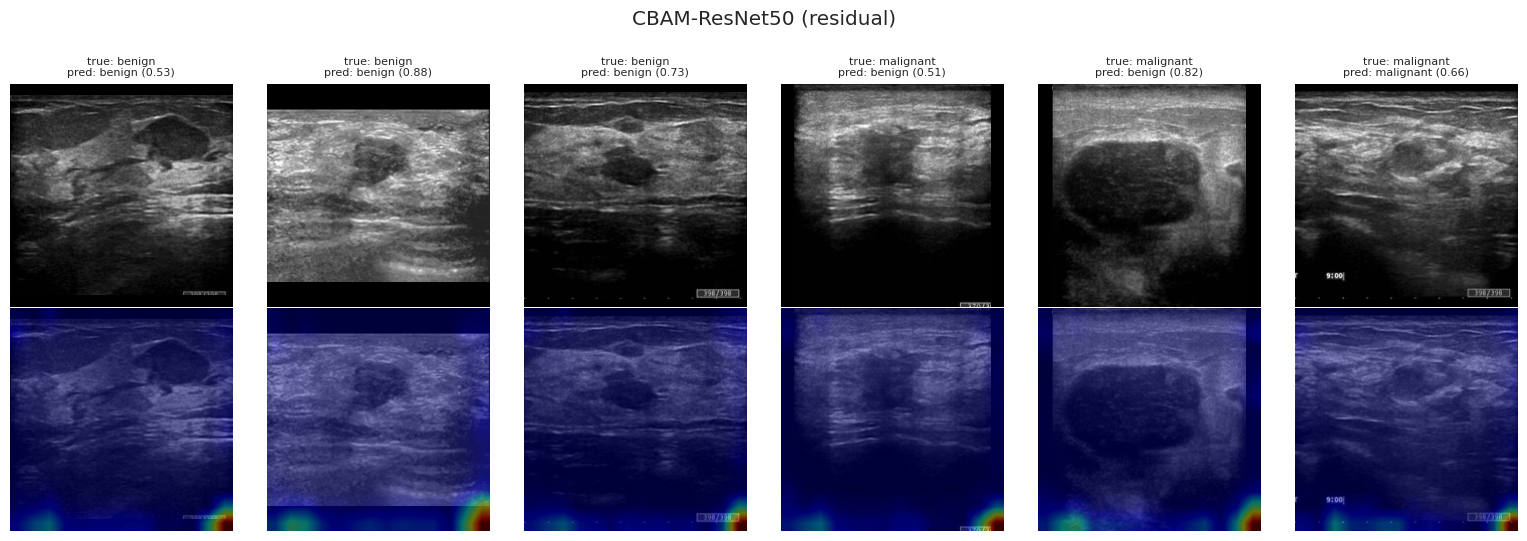

In [39]:
model = kept[PROPOSED]
cb = [mod for mod in model.modules() if isinstance(mod, CBAM)][2]      # stage-3 CBAM
sel = list(np.where(y_test == 0)[0][:3]) + list(np.where(y_test == 1)[0][:3])
dsT = BUSIData(test_idx); xb = torch.stack([dsT[i][0] for i in sel]).to(DEVICE)
model.eval()
with torch.no_grad(): out = torch.softmax(model(xb).float(), 1).cpu().numpy()
sa = F.interpolate(cb.last_sa.float(), size=(IMG, IMG), mode='bilinear', align_corners=False)[:, 0].cpu().numpy()
fig, ax = plt.subplots(2, len(sel), figsize=(2.6 * len(sel), 5.4))
for j, i in enumerate(sel):
    g = X_all[test_idx[i]]; ax[0, j].imshow(g, cmap='gray'); ax[0, j].axis('off')
    ax[0, j].set_title(f'true: {CLASSES[y_test[i]]}\npred: {CLASSES[out[j].argmax()]} ({out[j].max():.2f})', fontsize=8)
    ax[1, j].imshow(g, cmap='gray'); ax[1, j].imshow(sa[j], cmap='jet', alpha=0.45); ax[1, j].axis('off')
plt.suptitle(PROPOSED, y=1.0); plt.tight_layout(); plt.savefig(OUT_DIR / 'T2_spatial_attention_maps.png', dpi=150); plt.show()

## 9. Settings and reading of the results
*(Edit after you look at the tables and figures above: compare the mean difference between the attention model and plain ResNet50 with the seed-to-seed spread (sd). If the difference is smaller than the spread, say that attention shows no clear gain on this data, and give likely reasons. Report it honestly either way. The test set is small, so differences of a few points can be noise.)*

In [42]:
settings = pd.DataFrame({'Setting': ['Backbone', 'Attention', 'Input', 'Augmentation', 'Loss', 'Optimiser', 'LR (backbone / attention+head)', 'Schedule', 'Epochs / early stop', 'Batch size', 'Split', 'Seeds'],
    'Value': ['ResNet50 (ImageNet weights if available)', 'CBAM (channel + spatial, r=16, 7x7) after each of 4 stages; standard and residual variants', '224x224 letterboxed grayscale, 3 channels, ImageNet normalisation',
              'flip, rotation +-10, shift 5%, scale 0.9-1.1, brightness/contrast', 'Cross-entropy with class weights', 'AdamW, weight decay 1e-4', '1e-4 / 5e-4', 'Cosine annealing',
              '25 max, patience 6 on validation macro-F1', str(BS), 'patient-wise, stratified (train / val / test about 68 / 16 / 16 %)', ', '.join(map(str, SEEDS))]})
display(settings); settings.to_csv(OUT_DIR / 'proposed_settings.csv', index=False)

,Setting,Value
0,Backbone,ResNet50 (ImageNet weights if available)
1,Attention,"CBAM (channel + spatial, r=16, 7x7) after each..."
2,Input,"224x224 letterboxed grayscale, 3 channels, Ima..."
3,Augmentation,"flip, rotation +-10, shift 5%, scale 0.9-1.1, ..."
4,Loss,Cross-entropy with class weights
5,Optimiser,"AdamW, weight decay 1e-4"
6,LR (backbone / attention+head),1e-4 / 5e-4
7,Schedule,Cosine annealing
8,Epochs / early stop,"25 max, patience 6 on validation macro-F1"
9,Batch size,32
